# Module 5 — Seq2seq et attention

> **Objectif** : transformer une séquence en une autre séquence de longueur différente (traduction, résumé, normalisation, prédiction de structure…), découvrir pourquoi l'architecture encodeur-décodeur « classique » bute sur un **goulot d'étranglement**, et comment le **mécanisme d'attention** le supprime. L'attention est la brique centrale des Transformers : on la dérive mathématiquement (gradient compris), on la code en NumPy, on la regarde apprendre, puis on construit un traducteur de dates complet en PyTorch.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Modules 0 à 4 |
| **Librairies** | `numpy`, `matplotlib` ; `torch` pour les sections 6–8 |

**Plan**

1. Le problème seq2seq
2. L'encodeur-décodeur et son goulot d'étranglement
3. L'attention : intuition « dictionnaire flou »
4. Les maths de l'attention (Bahdanau, Luong) et leur gradient
5. Regarder l'attention apprendre (NumPy)
6. Les données : normaliser des dates écrites en langage naturel
7. Un seq2seq avec attention en PyTorch
8. Décodage, évaluation, visualisation des alignements
9. Vers le Transformer : requêtes, clés, valeurs
10. Récapitulatif et exercices

In [1]:
import datetime as dt

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

## 1. Le problème seq2seq

Beaucoup de tâches transforment une séquence $x_{1:S}$ en une séquence $y_{1:T}$, **avec $S\ne T$ en général et sans alignement un-pour-un** :

| Tâche | Entrée | Sortie |
|---|---|---|
| Traduction | « Le chat dort » | « The cat is sleeping » |
| Résumé | un article | 3 phrases |
| Normalisation | « mercredi 21 oct. 2026 » | `2026-10-21` |
| Correction | « je suis allé a la plage » | « je suis allé à la plage » |
| Biologie | une séquence | une annotation, une structure, une séquence « germinale » |

On modélise la distribution conditionnelle, toujours avec la règle de la chaîne :
$$
p(y_{1:T}\mid x_{1:S}) = \prod_{t=1}^{T} p(y_t\mid y_{<t},\, x_{1:S})
$$
C'est un **modèle de langue conditionnel** (module 4) : on génère la sortie token par token, mais chaque prédiction peut aussi consulter l'entrée.

## 2. L'encodeur-décodeur et son goulot d'étranglement

### 💡 Intuition

L'architecture de Sutskever et al. (2014) :
1. un **encodeur** (RNN) lit toute l'entrée et la résume dans son dernier état caché $h_S$ ;
2. un **décodeur** (un second RNN) part de ce résumé et génère la sortie token par token, comme un modèle de langue.

```
 ENCODEUR                              DÉCODEUR
 x1 → x2 → … → xS  ──►  [ h_S ]  ──►  y1 → y2 → … → yT <eos>
                       vecteur unique
                       de taille fixe
```

**Le goulot d'étranglement** : toute l'information de la phrase source, qu'elle fasse 5 ou 50 mots, doit tenir dans **un seul vecteur** de dimension fixe. En pratique, la qualité de traduction de ces modèles s'effondrait sur les phrases longues (Cho et al., 2014). Un traducteur humain ne fait pas ainsi : il **relit** la partie pertinente de la source au moment de traduire chaque mot.

### Entraînement : le *teacher forcing*

Pendant l'entraînement, à l'étape $t$, on donne au décodeur le **vrai** token précédent $y_{t-1}$ (et non sa propre prédiction). C'est rapide et stable, mais crée un décalage avec l'inférence, où le modèle consomme ses propres sorties, erreurs comprises (**exposure bias**). Remède partiel : le *scheduled sampling*, qui remplace parfois le vrai token par la prédiction pendant l'entraînement.

## 3. L'attention : un dictionnaire « flou »

### 💡 Intuition

À chaque pas de génération, au lieu d'utiliser un résumé figé, le décodeur :
1. formule une **requête** (« de quoi ai-je besoin maintenant ? ») à partir de son état ;
2. compare cette requête à **chaque** état de l'encodeur (les **clés**) pour obtenir des scores de pertinence ;
3. transforme ces scores en **poids** positifs sommant à 1 (softmax) ;
4. calcule la **moyenne pondérée** des états de l'encodeur (les **valeurs**) : c'est le **vecteur de contexte**, propre à ce pas de temps.

C'est un dictionnaire Python… mais flou : au lieu de renvoyer la valeur de **la** clé exactement égale à la requête, on renvoie un mélange des valeurs, pondéré par la **similarité** requête-clé.

In [2]:
# A "soft dictionary": keys are 2D unit vectors, values are scalars
keys = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]])
values = np.array([10.0, 20.0, 30.0, 40.0])
for query, temp in [([0.9, 0.1], 1.0), ([0.9, 0.1], 0.1), ([0.5, 0.5], 0.1)]:
    q = np.array(query); q /= np.linalg.norm(q)
    weights = softmax(keys @ q / temp)
    print(f"query={query}, temperature={temp}: weights={weights.round(3)} -> output = {weights @ values:.2f}")
print("hard dict lookup would return exactly one of", values)

query=[0.9, 0.1], temperature=1.0: weights=[0.531 0.22  0.073 0.176] -> output = 18.94
query=[0.9, 0.1], temperature=0.1: weights=[1. 0. 0. 0.] -> output = 10.00
query=[0.5, 0.5], temperature=0.1: weights=[0.5 0.5 0.  0. ] -> output = 15.00
hard dict lookup would return exactly one of [10. 20. 30. 40.]


Avec une température basse, l'attention se comporte comme une recherche exacte ; avec des scores modérés, elle **interpole**. Et surtout, contrairement à `dict[key]`, cette opération est **différentiable** : on peut apprendre où regarder par descente de gradient.

## 4. Les maths de l'attention

### 📐 Attention de Bahdanau (additive, 2015)

Soit $h_1,\dots,h_S$ les états de l'encodeur (souvent un BiGRU : $h_j=[\overrightarrow{h_j};\overleftarrow{h_j}]$) et $s_{t-1}$ l'état du décodeur. Pour chaque pas $t$ :

$$
\begin{aligned}
e_{tj} &= v^\top\tanh\left(W_s\,s_{t-1} + W_h\,h_j\right) &&\text{score d'alignement (un petit MLP)}\\
\alpha_{tj} &= \frac{\exp(e_{tj})}{\sum_{k=1}^{S}\exp(e_{tk})} &&\text{poids d'attention}\\
c_t &= \sum_{j=1}^{S}\alpha_{tj}\,h_j &&\text{vecteur de contexte}\\
s_t &= \mathrm{GRU}\big([E y_{t-1};\,c_t],\ s_{t-1}\big), \quad p(y_t\mid\cdot) = \mathrm{softmax}\big(W_o[s_t; c_t; E y_{t-1}]\big)
\end{aligned}
$$

### 📐 Attention de Luong (multiplicative, 2015)

Le score devient un produit scalaire, beaucoup moins cher (un produit matriciel pour toutes les positions) :
$$
e_{tj} = s_t^\top h_j \;\;(\text{dot})\qquad\text{ou}\qquad e_{tj} = s_t^\top W h_j\;\;(\text{general})
$$
Le Transformer utilise le produit scalaire **mis à l'échelle** par $1/\sqrt{d}$ (module 6).

### 📐 Masquage

Les entrées d'un batch sont paddées (module 1). On ne doit **jamais** attribuer de poids aux positions PAD : on met leur score à $-\infty$ avant la softmax, ce qui donne $\alpha = 0$ exactement.

### 📐 Le gradient à travers la softmax d'attention

Pour une ligne $\alpha = \mathrm{softmax}(e)$, sortie $c = \sum_j \alpha_j h_j$, et un gradient amont $g_c = \partial L/\partial c$ :
$$
\frac{\partial L}{\partial \alpha_j} = g_c^\top h_j =: \gamma_j,\qquad
\frac{\partial L}{\partial e_j} = \sum_k \frac{\partial L}{\partial\alpha_k}\,\alpha_k(\delta_{kj}-\alpha_j) = \alpha_j\big(\gamma_j - \textstyle\sum_k\alpha_k\gamma_k\big)
$$
**Interprétation** : le score de la position $j$ augmente si sa valeur $h_j$ est **plus utile que la moyenne actuelle** ($\gamma_j > \bar\gamma$). L'attention se renforce sur ce qui aide à réduire la perte. Et $\partial L/\partial h_j = \alpha_j\,g_c$ (+ la contribution via le score) : une position peu regardée reçoit peu de gradient.

In [3]:
# Numerical check of the attention-softmax gradient
S, d = 6, 4
e = rng.normal(size=S); h = rng.normal(size=(S, d)); g_c = rng.normal(size=d)
loss_fn = lambda e_: g_c @ (softmax(e_) @ h)            # L = g_c . c  => dL/dc = g_c
alpha = softmax(e)
gamma = h @ g_c
grad_analytic = alpha * (gamma - alpha @ gamma)
eps = 1e-6
grad_numeric = np.array([(loss_fn(e + eps * np.eye(S)[j]) - loss_fn(e - eps * np.eye(S)[j])) / (2 * eps) for j in range(S)])
print("analytic:", grad_analytic.round(6))
print("numeric :", grad_numeric.round(6))
print("sum of grads (always 0: shift-invariance of softmax):", grad_analytic.sum().round(12))

analytic: [-0.404423  0.055905  0.24346  -0.046948  0.006789  0.145217]
numeric : [-0.404423  0.055905  0.24346  -0.046948  0.006789  0.145217]
sum of grads (always 0: shift-invariance of softmax): -0.0


## 5. Regarder l'attention apprendre (NumPy)

Le plus petit modèle d'attention possible. Tâche : **inverser** une séquence de chiffres (`3 1 4 1 5` → `5 1 4 1 3`). La sortie à la position $i$ est un mélange des tokens d'entrée :
$$
p_i = \sum_j \alpha_{ij}\,\mathrm{onehot}(x_j), \qquad \alpha_{i,:} = \mathrm{softmax}(W_{i,:})
$$
Le seul paramètre est une matrice de scores $W\in\mathbb R^{T\times T}$ (une attention purement **positionnelle** : « la position de sortie $i$ regarde la position d'entrée $j$ »). La perte est l'entropie croisée $-\log p_i[y_i]$. On applique le gradient de la section 4 avec $\gamma_{ij} = \partial L/\partial\alpha_{ij} = -\mathrm{onehot}(x_j)[y_i]/p_i[y_i]$.

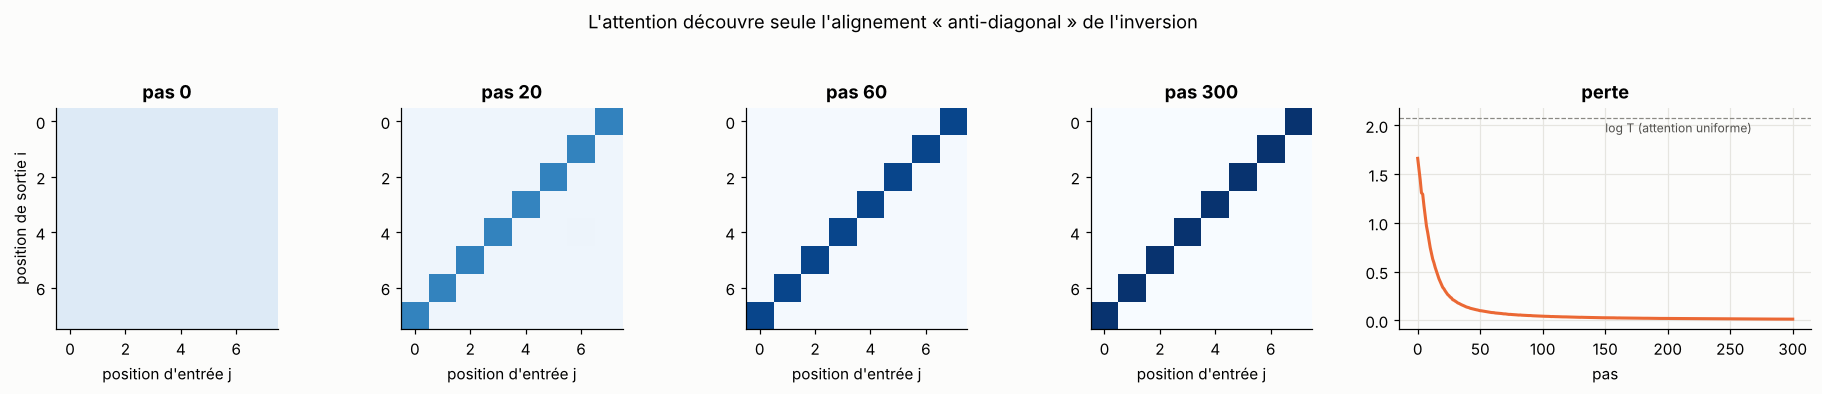

In [4]:
T_seq, K = 8, 10                                   # sequence length, number of distinct digits
W = np.zeros((T_seq, T_seq))                       # uniform attention at start
lr, snapshots, losses = 2.0, {}, []
r = np.random.default_rng(1)
for step in range(301):
    x = r.integers(0, K, (64, T_seq))              # batch of random sequences
    y = x[:, ::-1]                                 # target: reversed sequence
    A = softmax(W)                                 # (T, T), same for every example (positional attention)
    onehot = np.eye(K)[x]                          # (B, T, K)
    P = np.einsum("ij,bjk->bik", A, onehot)        # (B, T, K) predicted distributions
    p_true = np.take_along_axis(P, y[..., None], -1)[..., 0]    # (B, T)
    losses.append(-np.log(p_true + 1e-12).mean())
    # dL/dalpha_ij = -1[x_j == y_i] / p_i[y_i], averaged over the batch
    match = (x[:, None, :] == y[:, :, None]).astype(float)       # (B, T_out, T_in)
    gamma = -(match / p_true[..., None]).mean(0) / T_seq         # (T, T)
    grad_W = A * (gamma - (A * gamma).sum(1, keepdims=True))     # softmax backward, row by row
    W -= lr * grad_W
    if step in (0, 20, 60, 300):
        snapshots[step] = A.copy()

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.4]})
for ax, (s, A_) in zip(axes, snapshots.items()):
    ax.imshow(A_, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"pas {s}"); ax.set_xlabel("position d'entrée j"); ax.grid(False)
axes[0].set_ylabel("position de sortie i")
axes[4].plot(losses, color=PALETTE[1]); axes[4].set_title("perte"); axes[4].set_xlabel("pas")
axes[4].axhline(np.log(T_seq), color="#8a8984", ls="--", lw=0.8); axes[4].text(150, np.log(T_seq) - 0.15, "log T (attention uniforme)", fontsize=8, color="#52514e")
plt.suptitle("L'attention découvre seule l'alignement « anti-diagonal » de l'inversion", y=1.04)
plt.tight_layout(); plt.show()

Au départ, l'attention est uniforme : chaque sortie est la moyenne de toutes les entrées. La bonne réponse figure toujours dans la séquence, elle reçoit donc au moins $1/8$ de la probabilité : la perte initiale est inférieure à $\log 8$ (un peu moins quand un chiffre est répété). Le gradient renforce progressivement, pour chaque sortie $i$, la position $j = T-1-i$ qui « explique » systématiquement la cible : l'**alignement** émerge de la seule supervision des sorties. Dans un vrai modèle, les scores dépendent du **contenu** (de $s_{t-1}$ et $h_j$) et non seulement des positions, ce qui permet des alignements différents pour chaque exemple : c'est ce qu'on fait maintenant.

## 6. Les données : normaliser des dates

**Tâche** : convertir des dates écrites de façons très variées en format ISO `AAAA-MM-JJ`.

```
"mercredi 21 octobre 2026"  →  "2026-10-21"
"21/10/26"                  →  "2026-10-21"
"Oct 21, 2026"              →  "2026-10-21"
```

C'est un vrai problème seq2seq en miniature : longueurs variables, **réordonnancement** (le jour passe de la gauche à la droite), mots à convertir en nombres (« octobre » → `10`), informations redondantes à ignorer (le jour de la semaine). Et les alignements attendus sont **interprétables** : on saura vérifier si l'attention regarde au bon endroit.

In [5]:
MONTHS_FR = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre", "novembre", "décembre"]
MONTHS_FR_ABBR = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
MONTHS_EN = ["january", "february", "march", "april", "may", "june", "july", "august", "september", "october", "november", "december"]
DAYS_FR = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]


def random_date(r):
    start = dt.date(1950, 1, 1).toordinal()
    return dt.date.fromordinal(int(r.integers(start, dt.date(2049, 12, 31).toordinal())))


def format_date(d, r):
    m0 = d.month - 1
    fmts = [
        lambda: f"{d.day} {MONTHS_FR[m0]} {d.year}",
        lambda: f"{DAYS_FR[d.weekday()]} {d.day} {MONTHS_FR[m0]} {d.year}",
        lambda: f"le {d.day} {MONTHS_FR_ABBR[m0]} {d.year}",
        lambda: f"{d.day:02d}/{d.month:02d}/{d.year}",
        lambda: f"{d.day}/{d.month}/{d.year % 100:02d}",
        lambda: f"{d.day:02d}-{d.month:02d}-{d.year}",
        lambda: f"{MONTHS_EN[m0].capitalize()} {d.day}, {d.year}",
        lambda: f"{MONTHS_EN[m0][:3].capitalize()} {d.day} {d.year}",
        lambda: f"{d.year}.{d.month:02d}.{d.day:02d}",
        lambda: f"{d.day} {MONTHS_FR[m0].upper()} {d.year}",
    ]
    return fmts[r.integers(len(fmts))]()


r = np.random.default_rng(0)
pairs = []
for _ in range(30_000):
    d = random_date(r)
    pairs.append((format_date(d, r), d.isoformat()))
# two-digit years are ambiguous: we decide 00-49 -> 20xx, 50-99 -> 19xx, consistent with the 1950-2049 range
for src, tgt in pairs[:10]:
    print(f"{src:32s} -> {tgt}")
src_lens = [len(s) for s, _ in pairs]
print(f"\nsource length: min {min(src_lens)}, max {max(src_lens)}, mean {np.mean(src_lens):.1f} | target length: 10")

January 23, 2035                 -> 2035-01-23
le 10 févr. 2001                 -> 2001-02-10
13 octobre 1980                  -> 1980-10-13
11 juillet 1957                  -> 1957-07-11
1967.07.12                       -> 1967-07-12
10 DÉCEMBRE 2014                 -> 2014-12-10
May 12, 2000                     -> 2000-05-12
Jan 27 2047                      -> 2047-01-27
24-03-2013                       -> 2013-03-24
28 DÉCEMBRE 2005                 -> 2005-12-28

source length: min 6, max 26, mean 12.6 | target length: 10


> ⚠️ **Une ambiguïté bien réelle** : « 21/10/26 » est-il 1926 ou 2026 ? Nos données tirent les années entre 1950 et 2049, donc la règle implicite est « 00–49 → 20xx ». Le modèle l'apprendra sans qu'on la lui dise, ce qui est à la fois puissant et dangereux : un modèle apprend les **conventions cachées** de ses données d'entraînement, y compris celles qu'on n'a pas voulues.

In [6]:
SPECIALS = ["<pad>", "<sos>", "<eos>"]
src_vocab = SPECIALS + sorted({c for s, _ in pairs for c in s})
tgt_vocab = SPECIALS + sorted({c for _, t in pairs for c in t})
src_stoi = {c: i for i, c in enumerate(src_vocab)}
tgt_stoi = {c: i for i, c in enumerate(tgt_vocab)}
PAD, SOS, EOS = 0, 1, 2
print(f"source vocabulary: {len(src_vocab)} symbols | target vocabulary: {len(tgt_vocab)} symbols: {''.join(tgt_vocab[3:])}")

idx = np.random.default_rng(1).permutation(len(pairs))
train_pairs = [pairs[i] for i in idx[:27_000]]
val_pairs = [pairs[i] for i in idx[27_000:28_500]]
test_pairs = [pairs[i] for i in idx[28_500:]]

source vocabulary: 61 symbols | target vocabulary: 14 symbols: -0123456789


## 7. Un seq2seq avec attention en PyTorch

Architecture (fidèle à Bahdanau et al., 2015) :
- **encodeur** : embeddings de caractères → **GRU bidirectionnel** → états $h_j\in\mathbb R^{2H}$ ;
- **pont** : l'état initial du décodeur est $s_0 = \tanh(W[\overrightarrow{h_S};\overleftarrow{h_1}])$ ;
- **décodeur** : à chaque pas, attention additive sur les $h_j$ → contexte $c_t$ → `GRUCell` → logits.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)


def encode_batch(batch_pairs):
    src = [torch.tensor([src_stoi[c] for c in s]) for s, _ in batch_pairs]
    tgt = [torch.tensor([SOS] + [tgt_stoi[c] for c in t] + [EOS]) for _, t in batch_pairs]
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt = nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD)
    return src, tgt                                   # tgt[:, :-1] = decoder input, tgt[:, 1:] = targets


class Encoder(nn.Module):
    def __init__(self, V, d=64, H=128):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        self.rnn = nn.GRU(d, H, batch_first=True, bidirectional=True)
        self.bridge = nn.Linear(2 * H, H)

    def forward(self, src):
        lengths = (src != PAD).sum(1)
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(src), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, h_n = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=src.shape[1])
        s0 = torch.tanh(self.bridge(torch.cat([h_n[0], h_n[1]], dim=-1)))   # forward-last & backward-first
        return out, s0                                 # (B, S, 2H), (B, H)


class AdditiveAttention(nn.Module):
    def __init__(self, enc_dim, dec_dim, attn_dim=128):
        super().__init__()
        self.W_h = nn.Linear(enc_dim, attn_dim, bias=False)
        self.W_s = nn.Linear(dec_dim, attn_dim)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def precompute(self, enc_out):
        return self.W_h(enc_out)                       # (B, S, A): computed once per sentence

    def forward(self, s_prev, enc_out, enc_proj, src_mask):
        e = self.v(torch.tanh(enc_proj + self.W_s(s_prev).unsqueeze(1))).squeeze(-1)   # (B, S)
        e = e.masked_fill(~src_mask, float("-inf"))                                   # never attend to PAD
        alpha = torch.softmax(e, dim=-1)                                               # (B, S)
        context = torch.bmm(alpha.unsqueeze(1), enc_out).squeeze(1)                    # (B, 2H)
        return context, alpha


class Decoder(nn.Module):
    def __init__(self, V, d=64, H=128, enc_dim=256):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        self.attn = AdditiveAttention(enc_dim, H)
        self.cell = nn.GRUCell(d + enc_dim, H)
        self.out = nn.Linear(H + enc_dim + d, V)

    def step(self, y_prev, s_prev, enc_out, enc_proj, src_mask):
        e = self.emb(y_prev)                                          # (B, d)
        context, alpha = self.attn(s_prev, enc_out, enc_proj, src_mask)
        s = self.cell(torch.cat([e, context], dim=-1), s_prev)        # (B, H)
        logits = self.out(torch.cat([s, context, e], dim=-1))         # (B, V)
        return logits, s, alpha


class Seq2Seq(nn.Module):
    def __init__(self, V_src, V_tgt, H=128):
        super().__init__()
        self.encoder = Encoder(V_src, H=H)
        self.decoder = Decoder(V_tgt, H=H, enc_dim=2 * H)

    def forward(self, src, tgt_in, teacher_forcing=1.0):
        enc_out, s = self.encoder(src)
        enc_proj = self.decoder.attn.precompute(enc_out)
        src_mask = src != PAD
        y_prev = tgt_in[:, 0]                                         # <sos>
        all_logits, all_alpha = [], []
        for t in range(tgt_in.shape[1]):
            logits, s, alpha = self.decoder.step(y_prev, s, enc_out, enc_proj, src_mask)
            all_logits.append(logits); all_alpha.append(alpha)
            if t + 1 < tgt_in.shape[1]:
                use_gold = torch.rand(src.shape[0], device=src.device) < teacher_forcing
                y_prev = torch.where(use_gold, tgt_in[:, t + 1], logits.argmax(-1))
        return torch.stack(all_logits, 1), torch.stack(all_alpha, 1)  # (B, T, V), (B, T, S)


model = Seq2Seq(len(src_vocab), len(tgt_vocab)).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

In [ ]:
def run_epoch(model, data, opt=None, bs=128, teacher_forcing=1.0):
    training = opt is not None
    model.train(training)
    order = np.random.permutation(len(data)) if training else np.arange(len(data))
    total, n_tok = 0.0, 0
    with torch.set_grad_enabled(training):
        for k in range(0, len(data), bs):
            src, tgt = encode_batch([data[i] for i in order[k:k + bs]])
            src, tgt = src.to(device), tgt.to(device)
            logits, _ = model(src, tgt[:, :-1], teacher_forcing if training else 1.0)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt[:, 1:].reshape(-1), ignore_index=PAD)
            if training:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
            n = (tgt[:, 1:] != PAD).sum().item()
            total += loss.item() * n; n_tok += n
    return total / n_tok


opt = torch.optim.AdamW(model.parameters(), lr=2e-3)
history = []
for epoch in range(8):                    # ~1-2 min/epoch on CPU, seconds on GPU
    tf = max(0.5, 1.0 - 0.1 * epoch)      # scheduled sampling: slowly reduce teacher forcing
    tr = run_epoch(model, train_pairs, opt, teacher_forcing=tf)
    va = run_epoch(model, val_pairs)
    history.append((tr, va))
    print(f"epoch {epoch} | teacher forcing {tf:.1f} | train loss {tr:.4f} | val loss {va:.4f}")

## 8. Décodage, évaluation, visualisation des alignements

À l'inférence, pas de cible : on décode de façon **gloutonne** (argmax à chaque pas) jusqu'à `<eos>`. On mesure l'**exact match** (la date entière est correcte), bien plus exigeant que la précision par caractère.

In [ ]:
@torch.no_grad()
def translate(model, text, max_len=12):
    model.eval()
    src = torch.tensor([[src_stoi[c] for c in text]], device=device)
    enc_out, s = model.encoder(src)
    enc_proj = model.decoder.attn.precompute(enc_out)
    mask = src != PAD
    y, out, alphas = torch.tensor([SOS], device=device), [], []
    for _ in range(max_len):
        logits, s, alpha = model.decoder.step(y, s, enc_out, enc_proj, mask)
        y = logits.argmax(-1)
        if y.item() == EOS:
            break
        out.append(tgt_vocab[y.item()]); alphas.append(alpha[0].cpu().numpy())
    return "".join(out), np.array(alphas)


correct = sum(translate(model, s)[0] == t for s, t in test_pairs)
print(f"exact match on {len(test_pairs)} test dates: {correct / len(test_pairs):.1%}")
for s in ["mercredi 21 octobre 2026", "21/10/26", "Oct 21 2026", "le 1 janv. 2000", "29 février 2023", "3 décembre 1999"]:
    print(f"{s:28s} -> {translate(model, s)[0]}")

> 🔍 Teste « 29 février 2023 » : cette date **n'existe pas**. Le modèle produira quand même une sortie plausible (`2023-02-29`), avec la même assurance. Un modèle seq2seq ne vérifie aucune contrainte qu'on ne lui a pas apprise : à garder en tête pour toute application critique (et ce sera vrai des LLM).

In [ ]:
def plot_attention(text):
    pred, A = translate(model, text)
    fig, ax = plt.subplots(figsize=(0.38 * len(text) + 1.5, 0.38 * len(pred) + 1.2))
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(text))); ax.set_xticklabels(list(text), fontsize=9)
    ax.set_yticks(range(len(pred))); ax.set_yticklabels(list(pred), fontsize=9)
    ax.set_xlabel("entrée"); ax.set_ylabel("sortie générée"); ax.grid(False)
    ax.set_title(f"« {text} » → {pred}", fontsize=10)
    plt.show()

for s in ["mercredi 21 octobre 2026", "21/10/26", "Oct 21 2026"]:
    plot_attention(s)

**Ce que tu dois observer** (et vérifier, car c'est un excellent test de compréhension) :
- pour produire l'année `2026`, l'attention se porte sur `2026` (ou sur `26` dans « 21/10/26 », d'où le modèle doit déduire le siècle) ;
- pour le mois `10`, elle regarde « octobre » / « Oct » / « 10 » ; souvent la **fin** du mot, car le GRU bidirectionnel a déjà accumulé l'information du mot entier à cette position ;
- le jour de la semaine (« mercredi ») est **ignoré** : il est redondant ;
- l'ordre change selon le format : diagonale décalée pour `jj/mm/aa`, ordre différent pour le format anglais. **Chaque exemple a son propre alignement**, contrairement à la section 5.

> ⚠️ **L'attention n'est pas une explication.** Les poids d'attention montrent *où* le modèle puise son contexte, pas *pourquoi* il décide. Avec un encodeur bidirectionnel, l'information d'un token est diffusée dans ses voisins : une attention sur la position $j$ ne veut pas dire que seul le caractère $j$ compte (Jain & Wallace, 2019, « Attention is not Explanation »).

## 9. Vers le Transformer : requêtes, clés, valeurs

Réécrivons l'attention de façon générique. Trois rôles :
- **requête** $q$ : ce que je cherche (ici, l'état du décodeur) ;
- **clés** $k_j$ : l'étiquette de chaque élément consultable ;
- **valeurs** $v_j$ : le contenu renvoyé (ici, clés = valeurs = états de l'encodeur).

$$
\mathrm{Attention}(q, K, V) = \sum_j \mathrm{softmax}_j\big(\mathrm{score}(q, k_j)\big)\,v_j
$$

Deux observations ont mené au Transformer (Vaswani et al., 2017, « Attention Is All You Need ») :
1. **Pourquoi garder le RNN ?** Si l'attention permet de consulter n'importe quelle position, on peut s'en servir **dans l'encodeur lui-même** : chaque token formule une requête et consulte tous les autres tokens de la même phrase. C'est la **self-attention**. Tous les tokens se calculent **en parallèle**, et la distance entre deux tokens quelconques est d'un seul pas (contre $|i-j|$ pas dans un RNN).
2. **Avec des projections apprises** $q = W_Q x$, $k = W_K x$, $v = W_V x$ et un score $q^\top k/\sqrt{d}$, tout se réduit à des **produits matriciels**, l'opération que les GPU savent faire le plus vite.

In [7]:
# Self-attention in 6 lines of NumPy: every token attends to every token of the same sequence
T_tok, d_model = 5, 8
X = rng.normal(size=(T_tok, d_model))                       # 5 token vectors
W_Q, W_K, W_V = (rng.normal(size=(d_model, d_model)) / np.sqrt(d_model) for _ in range(3))
Q, Kmat, Vmat = X @ W_Q, X @ W_K, X @ W_V
A_self = softmax(Q @ Kmat.T / np.sqrt(d_model))             # (T, T): row i = where token i looks
out = A_self @ Vmat                                         # (T, d): new, contextualized token vectors
print("attention matrix (rows sum to 1):\n", A_self.round(2))
print("output shape:", out.shape)

attention matrix (rows sum to 1):
 [[0.34 0.1  0.2  0.25 0.12]
 [0.32 0.01 0.06 0.48 0.12]
 [0.07 0.11 0.49 0.23 0.12]
 [0.08 0.61 0.09 0.03 0.19]
 [0.18 0.   0.01 0.8  0.01]]
output shape: (5, 8)


C'est exactement la brique qu'on va développer, mettre à l'échelle et empiler au module 6.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Seq2seq | $p(y\mid x)=\prod_t p(y_t\mid y_{<t}, x)$ : modèle de langue conditionnel |
| Encodeur-décodeur | tout dans $h_S$ → goulot d'étranglement, échec sur les longues séquences |
| Teacher forcing | vrai token précédent à l'entraînement ; exposure bias ; scheduled sampling |
| Attention | scores → softmax → moyenne pondérée ; contexte propre à chaque pas |
| Bahdanau / Luong | $v^\top\tanh(W_s s + W_h h)$ vs $s^\top W h$ |
| Masque | score $=-\infty$ sur les PAD |
| Gradient | $\partial L/\partial e_j = \alpha_j(\gamma_j - \bar\gamma)$ |
| Interprétation | alignements lisibles, mais attention ≠ explication |
| Vers le Transformer | requêtes / clés / valeurs ; self-attention ; tout en produits matriciels |

### 🏋️ Exercices

1. **Sans attention.** Remplace le contexte $c_t$ par un vecteur nul (le décodeur n'a plus que $s_0$). Compare l'exact match. Puis entraîne les deux modèles sur des dates **plus longues** (ajoute l'heure : « 21 octobre 2026 à 14 h 35 »). Lequel se dégrade le plus ?
2. **Luong.** Remplace l'attention additive par une attention « general » $s^\top W h$. Compare vitesse et précision.
3. **Beam search.** Implémente un décodage en faisceau de largeur 3. Sur cette tâche quasi déterministe, aide-t-il ?
4. **Robustesse.** Évalue le modèle sur des formats **absents** de l'entraînement (« 21.10.2026 », « vingt et un octobre »). Que se passe-t-il ? Qu'est-ce que cela dit de la généralisation « hors distribution » ?
5. **Gradient de l'attention, version matricielle.** Pour $C = AV$ avec $A=\mathrm{softmax}(E)$ ligne par ligne, montre que $\partial L/\partial E = A\odot\big(G - \mathrm{rowsum}(A\odot G)\big)$ où $G = (\partial L/\partial C)\,V^\top$. C'est le calcul exact que fait PyTorch dans la self-attention.

<details><summary>Indications</summary>

1. Sans attention, le modèle apprend encore les formats courts (la séquence tient dans $s_0$), mais l'écart se creuse avec la longueur, c'est l'expérience historique de Bahdanau et al.
3. Sur une tâche où la bonne sortie a une probabilité proche de 1, greedy et beam coïncident presque toujours.
4. Les sorties sont souvent absurdes mais très « confiantes » : le modèle n'a appris que la distribution vue à l'entraînement.
5. Applique la formule de la section 4 à chaque ligne $i$ : $\gamma_{ij} = (\partial L/\partial C)_{i,:}\cdot V_{j,:} = G_{ij}$.
</details>

**➡️ Module suivant : le Transformer de zéro** (attention mise à l'échelle et pourquoi $\sqrt{d}$, multi-têtes, encodages de position, masques, LayerNorm, connexions résiduelles, et un mini-GPT complet).